# Task 5: Analyse Predictions and Adversarial Examples

Setup

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from cifar_data import CLASS_NAMES, get_split, load_cifar10, prepare_inputs
from models.alexnet import AlexNet
from models.resnet import ResNet18
from train import CHECKPOINT_DIR, Run, get_device, run_experiment

device = get_device()
NUM_WORKERS = 2 if device.type == "cuda" else 0

data = load_cifar10()
split = get_split(data["train"])
stats = split["stats"]
X_test = torch.tensor(data["test"].data).permute(0, 3, 1, 2).float() / 255  # raw [0, 1], normalised inside prepare_inputs
y_test = torch.tensor(data["test"].targets)
print("torch", torch.__version__, "| device", device)

torch 2.11.0+cu128 | device cuda


Load the baseline models (trains only if a checkpoint is missing)

In [16]:
EPOCHS = 15
CONFIGS = {"alexnet": (AlexNet, 0.01), "resnet18": (ResNet18, 0.1)}

def train_or_load(model_class, run):
    path = CHECKPOINT_DIR / f"{run.name}_seed{run.seed}.pt"
    if path.exists():
        ckpt = torch.load(path, map_location=device)
        model = model_class(**run.options).to(device)
        model.load_state_dict(ckpt["state_dict"])
        return model, ckpt["history"], ckpt["summary"]
    return run_experiment(run, model_class, data, split, device, num_workers=NUM_WORKERS)

models, histories = {}, {}
for arch, (model_class, lr) in CONFIGS.items():  # baselines only - augmentation was analysed in Task 4
    name = f"{arch}_baseline"
    models[name], histories[name], _ = train_or_load(model_class, Run(name, epochs=EPOCHS, lr=lr))
    models[name].eval()

Training diagnostics

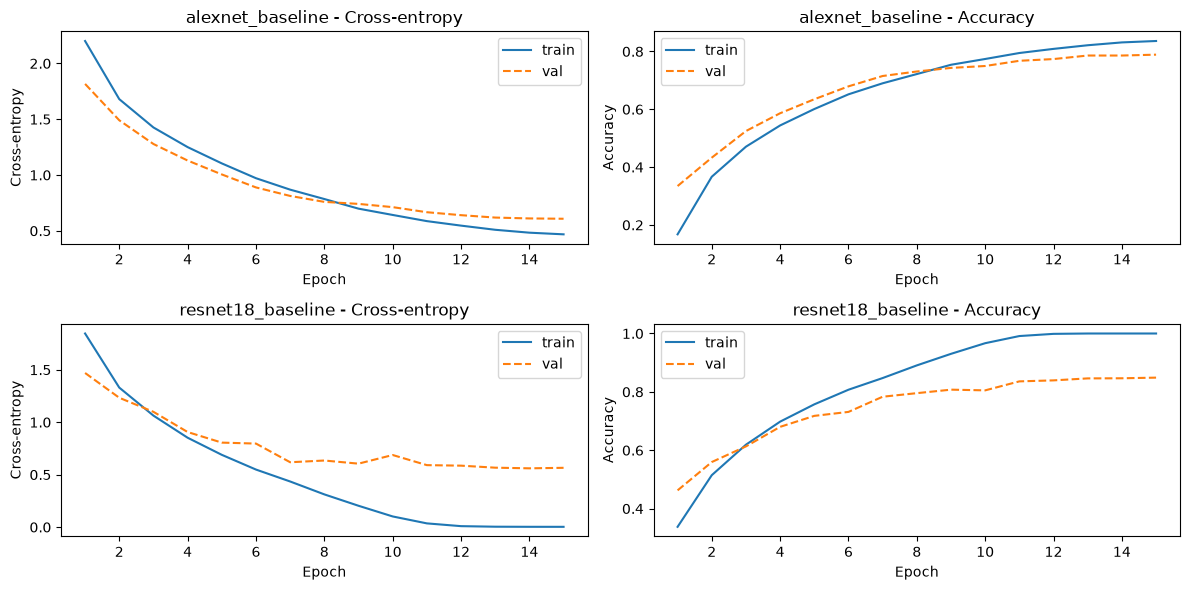

In [17]:
fig, axes = plt.subplots(len(histories), 2, figsize=(12, 3 * len(histories)))
for row, (name, h) in zip(axes, histories.items()):
    epochs = [r["epoch"] for r in h]
    for ax, metric, label in zip(row, ["ce", "accuracy"], ["Cross-entropy", "Accuracy"]):
        ax.plot(epochs, [r[f"train_{metric}"] for r in h], label="train")
        ax.plot(epochs, [r[f"val_{metric}"] for r in h], "--", label="val")
        ax.set(title=f"{name} - {label}", xlabel="Epoch", ylabel=label); ax.legend()
plt.tight_layout(); plt.show()

Test-set metrics: accuracy, per-class precision/recall, confusion matrices

alexnet_baseline     0.7852
resnet18_baseline    0.8481
Name: test accuracy, dtype: float64

alexnet_baseline        resnet18_baseline       
                  precision recall         precision recall
airplane              0.794  0.815             0.861  0.879
automobile            0.895  0.890             0.942  0.926
bird                  0.683  0.696             0.794  0.782
cat                   0.631  0.589             0.699  0.699
deer                  0.751  0.749             0.817  0.829
dog                   0.688  0.673             0.763  0.793
frog                  0.829  0.854             0.893  0.865
horse                 0.833  0.831             0.898  0.865
ship                  0.866  0.900             0.929  0.915
truck                 0.867  0.855             0.892  0.928
macro avg             0.784  0.785             0.849  0.848

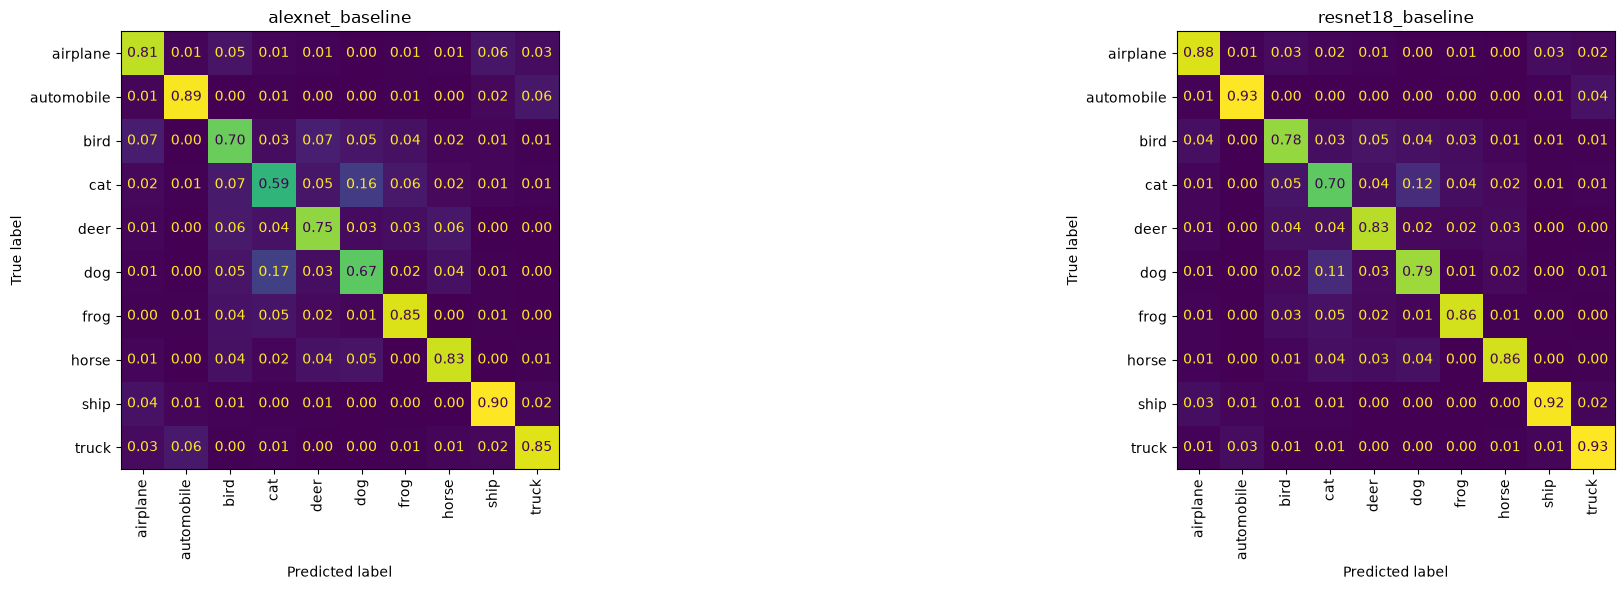

In [18]:
@torch.inference_mode()
def predict_proba(model, X, batch_size=512):
    return torch.cat([model(prepare_inputs(X[i:i + batch_size].to(device), stats)).softmax(1).cpu()
                      for i in range(0, len(X), batch_size)])

probs = {m: predict_proba(model, X_test) for m, model in models.items()}
preds = {m: p.argmax(1) for m, p in probs.items()}
report = {m: classification_report(y_test, preds[m], target_names=CLASS_NAMES, output_dict=True) for m in models}

display(pd.Series({m: report[m]["accuracy"] for m in models}, name="test accuracy").round(4))
display(pd.DataFrame({(m, k): {c: report[m][c][k] for c in CLASS_NAMES + ["macro avg"]}
                      for m in models for k in ["precision", "recall"]}).round(3))

fig, axes = plt.subplots(1, len(models), figsize=(24, 6))
for ax, m in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[m], display_labels=CLASS_NAMES, normalize="true",
                                            values_format=".2f", xticks_rotation=90, colorbar=False, ax=ax)
    ax.set_title(m)
plt.tight_layout(); plt.show()

Random correct and incorrect predictions (true → predicted, confidence)

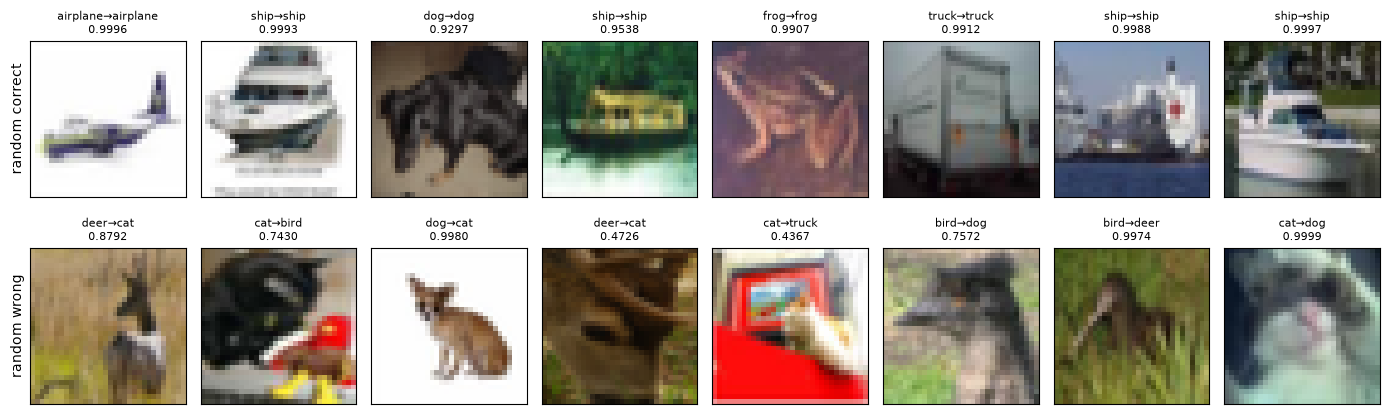

In [22]:
MODEL = "resnet18_baseline"  # model to inspect and attack

conf, pred = probs[MODEL].max(1)
correct = pred == y_test
g = torch.Generator().manual_seed(0)  # random but reproducible picks
pick = lambda mask: mask.nonzero().flatten()[torch.randperm(int(mask.sum()), generator=g)[:8]]
groups = {"random correct": pick(correct), "random wrong": pick(~correct)}

fig, axes = plt.subplots(2, 8, figsize=(14, 4.5))
for row, (title, idx) in zip(axes, groups.items()):
    for ax, i in zip(row, idx):
        ax.imshow(X_test[i].permute(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{CLASS_NAMES[y_test[i]]}→{CLASS_NAMES[pred[i]]}\n{conf[i]:.4f}", fontsize=8)
    row[0].set_ylabel(title)
plt.tight_layout(); plt.show()

Adversarial example: FGSM (ε = 4/255) vs random noise of the same size

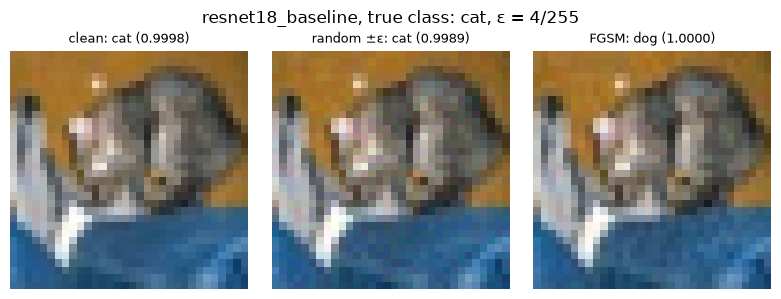

In [ ]:
def fgsm(model, raw, target, epsilon):
    # FGSM: as used in Lab2 A8. (Fast Gradient Sign Method)
    attack_input = raw.clone().requires_grad_(True)
    attack_loss = torch.nn.functional.cross_entropy(model(prepare_inputs(attack_input, stats)), target)
    (pixel_gradient,) = torch.autograd.grad(attack_loss, attack_input)
    return (attack_input + epsilon * pixel_gradient.sign()).clamp(0, 1).detach()

attacked_model = models[MODEL]
image_index = int(correct.nonzero()[0])  # first test image the model classifies correctly
image, label = X_test[image_index], int(y_test[image_index])
EPSILON = 4 / 255  # perturbation constant used for both fgsm and noise.

clean_image = image.unsqueeze(0).to(device)
fgsm_image = fgsm(attacked_model, clean_image, torch.tensor([label], device=device), EPSILON)
torch.manual_seed(0)  # random ±epsilon perturbation of the same size, for comparison
random_image = (clean_image + EPSILON * torch.randn_like(clean_image).sign()).clamp(0, 1)

images = {"clean": clean_image, "random ±ε": random_image, "FGSM": fgsm_image}
image_probs = predict_proba(attacked_model, torch.cat(list(images.values())))
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, (k, img), prob in zip(axes, images.items(), image_probs):
    ax.imshow(img[0].cpu().permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"{k}: {CLASS_NAMES[prob.argmax()]} ({prob.max():.4f})", fontsize=9)
fig.suptitle(f"{MODEL}, true class: {CLASS_NAMES[label]}, ε = 4/255"); plt.tight_layout(); plt.show()


Random vs adversarial perturbation over the first 1000 test images (ε = 4/255)

In [39]:
N, B = 1000, 250  # first N test images, attacked in batches of B
x_clean, y = X_test[:N], y_test[:N]
torch.manual_seed(0)
x_random = (x_clean + EPSILON * torch.randn_like(x_clean).sign()).clamp(0, 1)

accuracy = {}
for m, model in models.items():
    x_fgsm = torch.cat([fgsm(model, x_clean[i:i + B].to(device), y[i:i + B].to(device), EPSILON).cpu()
                        for i in range(0, N, B)])
    accuracy[m] = {k: (predict_proba(model, v).argmax(1) == y).float().mean().item()
                   for k, v in {"clean": x_clean, "random ±ε": x_random, "FGSM": x_fgsm}.items()}
display(pd.DataFrame(accuracy).T.round(3))


,clean,random ±ε,FGSM
alexnet_baseline,0.788,0.775,0.174
resnet18_baseline,0.857,0.849,0.100
